In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt 

In [3]:
# TASK 28,GroupBy Master: Load any sales or transaction dataset. Using groupby().agg(), compute: total revenue per region, average order value per customer segment, top product by quantity per month, and count of transactions per day of week. Plot the results.

In [4]:
# Loading the dataset
sales_df = pd.read_csv("SuperStoreOrders.csv")

In [5]:
sales_df.head() 

,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority,year
0,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,Office Supplies,Storage,"Tenex Lockers, Blue",408,2,0.0,106.140,35.46,Medium,2011
1,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Office Supplies,Supplies,"Acme Trimmer, High Speed",120,3,0.1,36.036,9.72,Medium,2011
2,HU-2011-1220,1/1/2011,5/1/2011,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,Office Supplies,Storage,"Tenex Box, Single Width",66,4,0.0,29.640,8.17,High,2011
3,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,Office Supplies,Paper,"Enermax Note Cards, Premium",45,3,0.5,-26.055,4.82,High,2011
4,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",114,5,0.1,37.770,4.70,Medium,2011


In [6]:
#checking the columns of  sales_df
sales_df.columns 

Index(['order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_name',
       'segment', 'state', 'country', 'market', 'region', 'product_id',
       'category', 'sub_category', 'product_name', 'sales', 'quantity',
       'discount', 'profit', 'shipping_cost', 'order_priority', 'year'],
      dtype='object')

In [7]:
#Using groupby().agg() to compute the following 

In [8]:
#checking of the sales column is numeric such that one can perform calculations using it 
sales_df["sales"].dtype

dtype('O')

In [9]:
#converting the column to numeric 
sales_df["sales"]=pd.to_numeric(sales_df["sales"],errors="coerce")

In [10]:
#i,Total revenue per region 
#Sales represent the revenue or sales_value
revenue_by_region = sales_df.groupby("region").agg(total_revenue=("sales","sum")).reset_index()
revenue_by_region

,region,total_revenue
0,Africa,538115.0
1,Canada,50314.0
2,Caribbean,251441.0
3,Central,1806638.0
4,Central Asia,389506.0
5,EMEA,575562.0
6,East,366492.0
7,North,790546.0
8,North Asia,453686.0
9,Oceania,625382.0


In [11]:
#ii, Average order value per customer segment 
# firstly to go about this problem, we have to understand that the value  of an order is the total sale made from that order

In [12]:
#We start by identifying each order using order_id.After that, we get the total value for each segment wrt the order_id and lastly we find the average

order_value =  sales_df.groupby(["order_id","segment"]).agg(order_values=("sales","sum")).reset_index()
order_value.head(20)

# This will ensure that we ar not calculating but order value per row but we are rather calculating order value per order(an order is idenfied by an order_id) which will later be used to calculate avg_order_value per segment in teh next  cell

,order_id,segment,order_values
0,AE-2011-9160,Consumer,161.0
1,AE-2013-1130,Consumer,229.0
2,AE-2013-1530,Corporate,24.0
3,AE-2014-2840,Consumer,42.0
4,AE-2014-3830,Consumer,280.0
5,AE-2014-4120,Consumer,6.0
6,AG-2011-1070,Corporate,309.0
7,AG-2011-1390,Home Office,607.0
8,AG-2011-1440,Consumer,59.0
9,AG-2011-2040,Consumer,408.0


In [13]:
# After getting order_value, we the calculate the average order value per segment
avg_order_value = order_value.groupby("segment").agg(avg_order_value=("order_values","mean")).reset_index()
avg_order_value

,segment,avg_order_value
0,Consumer,309.685440
1,Corporate,308.778965
2,Home Office,300.351824


In [14]:
#We need month and day of the week for the next two task so we use the date column to create a column for days and month as shown
sales_df["order_date"].dtype
#we covert the date entries to correct dates rather than using the dates as strings 
sales_df["order_date"] = pd.to_datetime(sales_df["order_date"],format="mixed",dayfirst=True,errors="coerce")


In [15]:
# Now checking the datatype to see if conversion was successful
sales_df["order_date"].dtype

dtype('<M8[ns]')

In [16]:
# Now creating the month and day feature from date 
sales_df["month"] = sales_df["order_date"].dt.month_name()
sales_df["day_of_week"] = sales_df["order_date"].dt.day_name()

In [17]:
#iii Calculating the top product by quantity per month
top_product_by_qty = sales_df.groupby(["product_name","month"]).agg(total_quantity=("quantity","sum")).reset_index().sort_values(by="total_quantity",ascending=False)
top_product_by_qty

,product_name,month,total_quantity
22125,Staples,November,121
22118,Staples,December,115
22127,Staples,September,113
22126,Staples,October,73
22123,Staples,March,68
...,...,...,...
23010,"Tenex Door Stop, Duo Pack",November,1
18809,"Rogers Shelving, Industrial",January,1
18802,"Rogers Shelving, Blue",May,1
3298,"BIC Markers, Water Color",January,1


In [18]:
#iv,Count of transactions per day of week. Plot the results. 
daily_transaction = sales_df.groupby("day_of_week").agg(daily_transaction_count_per_week=("order_id","count")).reset_index()
daily_transaction

,day_of_week,daily_transaction_count_per_week
0,Friday,9348
1,Monday,9177
2,Saturday,4580
3,Sunday,990
4,Thursday,8871
5,Tuesday,9307
6,Wednesday,9017


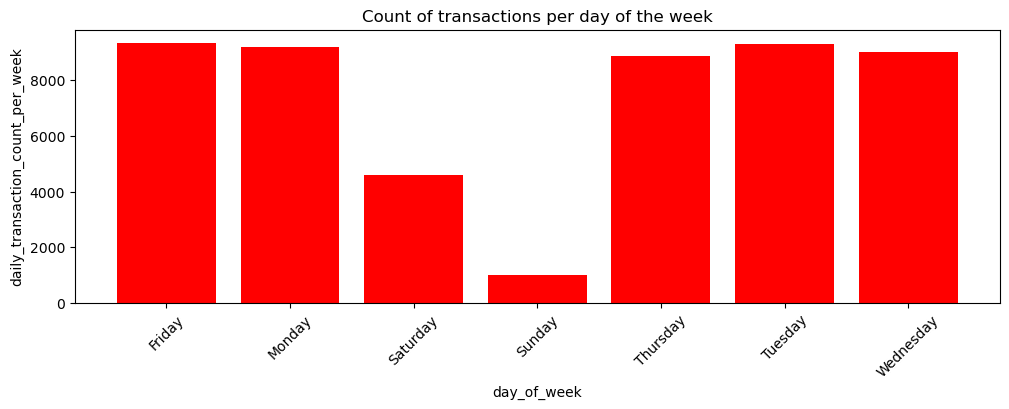

In [19]:
# PLOTTING EACH FINDING

#1, plotting the count of transaction per day of the week

plt.figure(figsize=(10,4))
plt.bar(daily_transaction["day_of_week"],
        daily_transaction["daily_transaction_count_per_week"], 
        color = "red"
        )

#costumizations 
plt.xticks(rotation=45)
plt.title("Count of transactions per day of the week")
plt.tight_layout()
plt.ylabel("daily_transaction_count_per_week")
plt.xlabel("day_of_week")
plt.show()



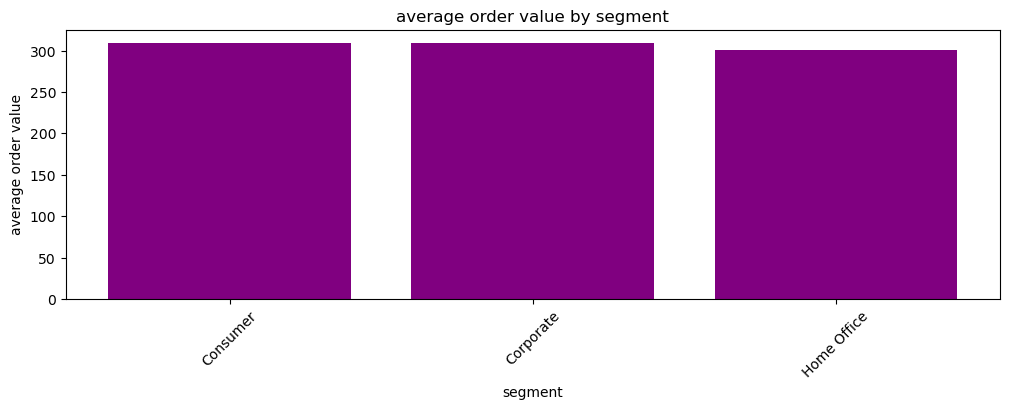

In [20]:
#2 plotting the average order value by segment
plt.figure(figsize=(10,4))
plt.bar(avg_order_value["segment"],
        avg_order_value["avg_order_value"], 
        color = "purple"
        )

#costumizations 
plt.xticks(rotation=45)
plt.title("average order value by segment")
plt.tight_layout()
plt.ylabel("average order value")
plt.xlabel("segment")
plt.show()

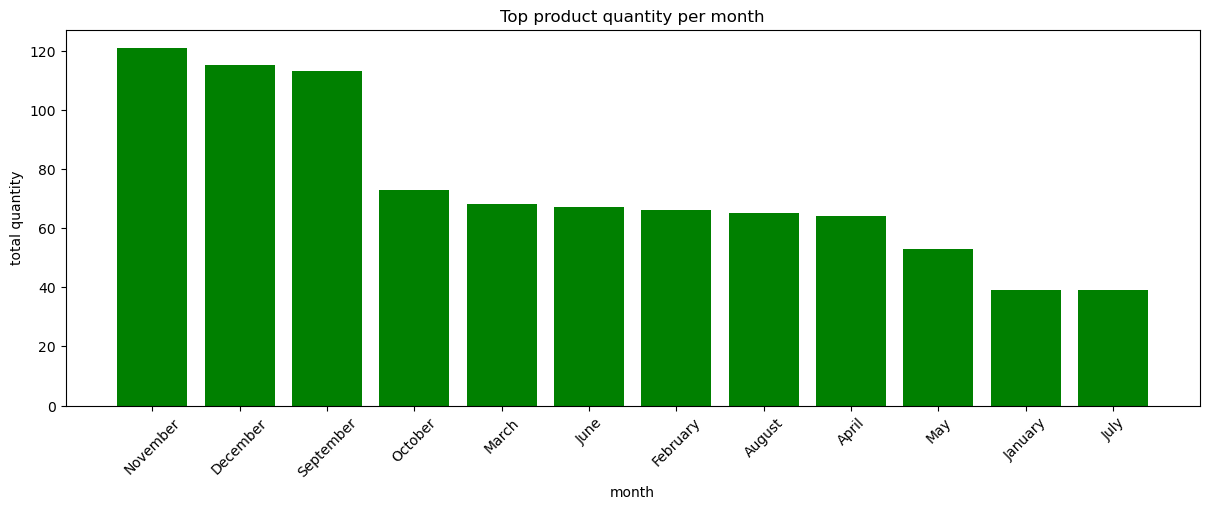

In [21]:
#3 Top product quantity per month
plt.figure(figsize=(12,5))
plt.bar(top_product_by_qty["month"],
        top_product_by_qty["total_quantity"], 
        color = "green"
        )

#costumizations 
plt.xticks(rotation=45)
plt.title("Top product quantity per month")
plt.tight_layout()
plt.ylabel("total quantity")
plt.xlabel("month")
plt.show()


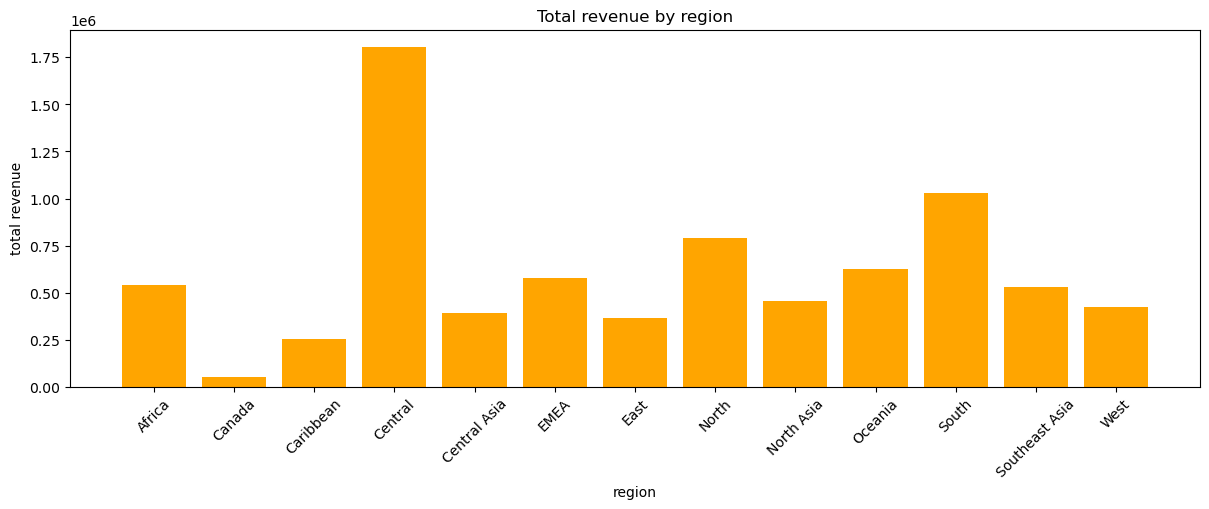

In [22]:
#4 Total Revenue by region 

plt.figure(figsize=(12,5))
plt.bar(revenue_by_region["region"],
        revenue_by_region["total_revenue"], 
        color = "orange"
        )

#costumizations 
plt.xticks(rotation=45)
plt.title("Total revenue by region")
plt.tight_layout()
plt.ylabel("total revenue")
plt.xlabel("region")
plt.show()

In [23]:
#TASK 29 
#Datetime Feature Extractor: Load a dataset with timestamps (e.g. order dates, sensor readings). Extract: year, month, day_of_week, hour, is_weekend (bool), season. Use these new columns to analyse patterns (e.g., "are Fridays the highest revenue day?"). 

In [24]:
#i, Loading Dataset
df = pd.read_csv("SuperMarket Analysis.csv")

df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [25]:
#Checking the available columns
print(df.columns.tolist())

['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date', 'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income', 'Rating']


In [26]:
#ii, Creating a timestamp by combining date and time. This time stamp will later be used to extract other features like year,month and hour etc...
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"]
)

df[["Date", "Time", "Datetime"]].head()

C:\Users\The_Lord\AppData\Local\Temp\ipykernel_7352\3205666210.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Datetime"] = pd.to_datetime(


,Date,Time,Datetime
0,1/5/2019,1:08:00 PM,2019-01-05 13:08:00
1,3/8/2019,10:29:00 AM,2019-03-08 10:29:00
2,3/3/2019,1:23:00 PM,2019-03-03 13:23:00
3,1/27/2019,8:33:00 PM,2019-01-27 20:33:00
4,2/8/2019,10:37:00 AM,2019-02-08 10:37:00


In [27]:
#iv,Extracting date from Datetime
df["year"] = df["Datetime"].dt.year

df[["Datetime","year"]].head()

,Datetime,year
0,2019-01-05 13:08:00,2019
1,2019-03-08 10:29:00,2019
2,2019-03-03 13:23:00,2019
3,2019-01-27 20:33:00,2019
4,2019-02-08 10:37:00,2019


In [28]:
#v, Extracting month from date time
df["month"] = df["Datetime"].dt.month_name()

df[["Datetime","month"]].head()

,Datetime,month
0,2019-01-05 13:08:00,January
1,2019-03-08 10:29:00,March
2,2019-03-03 13:23:00,March
3,2019-01-27 20:33:00,January
4,2019-02-08 10:37:00,February


In [29]:
#vi Extracting day of the week
df["day_of_week"] = df["Datetime"].dt.day_name()


df[["Datetime","day_of_week"]].head()

,Datetime,day_of_week
0,2019-01-05 13:08:00,Saturday
1,2019-03-08 10:29:00,Friday
2,2019-03-03 13:23:00,Sunday
3,2019-01-27 20:33:00,Sunday
4,2019-02-08 10:37:00,Friday


In [30]:
#vii, Extracting hour 
df["hour"] = df["Datetime"].dt.hour

df[["Datetime","hour"]].head()

,Datetime,hour
0,2019-01-05 13:08:00,13
1,2019-03-08 10:29:00,10
2,2019-03-03 13:23:00,13
3,2019-01-27 20:33:00,20
4,2019-02-08 10:37:00,10


In [31]:
#viii, Extracting is_weekend column which determines of a day is weekend or not and returns boolean
df["is_weekend"] = df["Datetime"].dt.day_of_week >= 5
df[["Datetime","is_weekend"]].head()
 

,Datetime,is_weekend
0,2019-01-05 13:08:00,True
1,2019-03-08 10:29:00,False
2,2019-03-03 13:23:00,True
3,2019-01-27 20:33:00,True
4,2019-02-08 10:37:00,False


In [32]:
#ix, Extracting or creating season
# we will manually define season based on month
def get_season(month):
    if month in ["December", "january", "February"]:
        return "Winter"
    elif month in ["March", "April", "May"]:
        return "Spring"
    elif month in ["June", "July", "August"]:
        return "Summer"
    else:
        return "Autumn"

df["season"] = df["month"].apply(get_season)

df[["month","season"]].head(20)

,month,season
0,January,Autumn
1,March,Spring
2,March,Spring
3,January,Autumn
4,February,Winter
5,March,Spring
6,February,Winter
7,February,Winter
8,January,Autumn
9,February,Winter


In [33]:
#x, Displaying all Extracted Features
df

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,...,gross margin percentage,gross income,Rating,Datetime,year,month,day_of_week,hour,is_weekend,season
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,...,4.761905,26.1415,9.1,2019-01-05 13:08:00,2019,January,Saturday,13,True,Autumn
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,...,4.761905,3.8200,9.6,2019-03-08 10:29:00,2019,March,Friday,10,False,Spring
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,...,4.761905,16.2155,7.4,2019-03-03 13:23:00,2019,March,Sunday,13,True,Spring
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,...,4.761905,23.2880,8.4,2019-01-27 20:33:00,2019,January,Sunday,20,True,Autumn
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,...,4.761905,30.2085,5.3,2019-02-08 10:37:00,2019,February,Friday,10,False,Winter
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,233-67-5758,Giza,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,...,4.761905,2.0175,6.2,2019-01-29 13:46:00,2019,January,Tuesday,13,False,Autumn
996,303-96-2227,Cairo,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,...,4.761905,48.6900,4.4,2019-03-02 17:16:00,2019,March,Saturday,17,True,Spring
997,727-02-1313,Alex,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.4320,...,4.761905,1.5920,7.7,2019-02-09 13:22:00,2019,February,Saturday,13,True,Winter
998,347-56-2442,Alex,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110,...,4.761905,3.2910,4.1,2019-02-22 15:33:00,2019,February,Friday,15,False,Winter


In [34]:
# Using the new columns to analyse patterns
#i, Revenue by day
df["revenue"] = df["Unit price"] * df["Quantity"]
revenue_by_day = df.groupby("day_of_week")["revenue"].sum().sort_values()

revenue_by_day

day_of_week
Monday       36094.36
Wednesday    41648.70
Friday       41834.61
Sunday       42340.85
Thursday     43189.76
Tuesday      49030.71
Saturday     53448.39
Name: revenue, dtype: float64

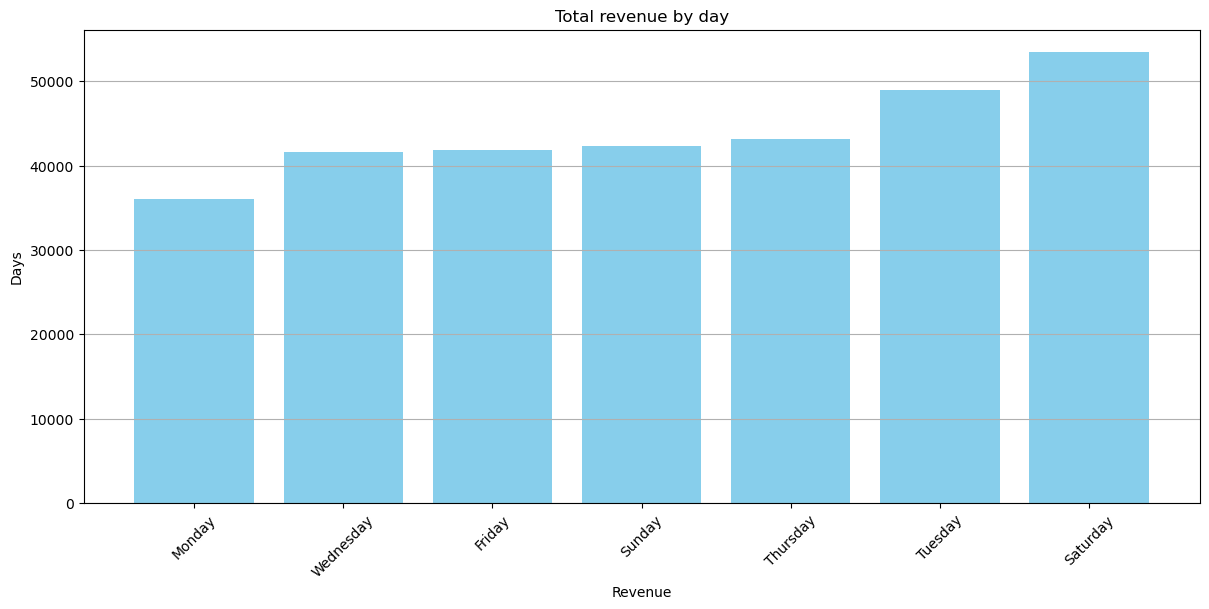

In [35]:

import matplotlib.pyplot as plt
plt.figure(figsize=(12,6))
plt.bar(revenue_by_day.index,
        revenue_by_day.values, 
        color = "skyblue"
        )

#costumizations 
plt.xticks(rotation=45)
plt.grid(axis = "y")
plt.title("Total revenue by day")
plt.tight_layout()
plt.ylabel("Days")
plt.xlabel("Revenue")
plt.show()

In [36]:
#ii, Revenue by hour
revenue_by_hour=df.groupby("hour")["revenue"].sum()
revenue_by_hour


hour
10    29925.22
11    28930.79
12    24824.65
13    33069.74
14    29360.38
15    29694.77
16    24025.07
17    23281.16
18    24790.80
19    37809.06
20    21875.74
Name: revenue, dtype: float64

In [37]:
# Getting the highest revenue hour
peak_hour = revenue_by_hour.idxmax()
peak_hour_revenue = revenue_by_hour.max()

print("Peak revenue hour:", peak_hour)
print("Revenue:", round(peak_hour_revenue, 2))

Peak revenue hour: 19
Revenue: 37809.06
